<a href="https://colab.research.google.com/github/Akash-Paunikar14/BiLens-Metadata-Aware-Fashion-Recommendation/blob/main/Multimodal_Product_Recommendation_Using_Transformer_Based_Text_and_Visual_Representation_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

***1. BiLens: Metadata-Aware Multimodal Fashion Recommendation System***


***2.Install Required Libraries and Dependencies***


In [ ]:
import pandas as pd
import numpy as np
import torch
import transformers

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Transformers:", transformers.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Pandas: 2.2.3
NumPy: 2.2.6
Transformers: 4.49.0
GPU available: True
GPU: Tesla T4



***3. Import Libraries and Configure the Environmen***t


In [ ]:

import os, gc, re, pickle, math, random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from PIL import Image, ImageFilter, ImageEnhance
from tqdm.auto import tqdm
from sklearn.metrics.pairwise import cosine_similarity

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Start small for the free Colab tier.
MAX_PRODUCTS = 100
TOP_K = 5
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

WORK = Path("/content/bilens_project")
DATA = WORK / "data"
IMAGES = DATA / "images"
INDEX = WORK / "index"

DATA.mkdir(parents=True, exist_ok=True)
IMAGES.mkdir(parents=True, exist_ok=True)
INDEX.mkdir(parents=True, exist_ok=True)

print("Working directory:", WORK)


PyTorch: 2.11.0+cu130
CUDA: True
GPU: Tesla T4
Working directory: /content/bilens_project


In [ ]:
import numpy as np
import scipy
import sklearn
from sklearn.metrics.pairwise import cosine_similarity

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("scikit-learn:", sklearn.__version__)
print("Imports successful!")

NumPy: 2.2.6
SciPy: 1.18.1
scikit-learn: 1.9.1
Imports successful!



***4.Load and Prepare the Fashion Product Dataset***


In [ ]:

import kagglehub

dataset_path = kagglehub.dataset_download("paramaggarwal/fashion-product-images-small")
print("Downloaded to:", dataset_path)


Using Colab cache for faster access to the 'fashion-product-images-small' dataset.
Downloaded to: /kaggle/input/fashion-product-images-small


In [ ]:

# Locate styles.csv and images automatically.
dataset_root = Path(dataset_path)

styles_candidates = list(dataset_root.rglob("styles.csv"))
image_dirs = [p for p in dataset_root.rglob("images") if p.is_dir()]

print("styles.csv:", styles_candidates[:3])
print("image directories:", image_dirs[:3])

assert styles_candidates, "styles.csv was not found."
assert image_dirs, "images directory was not found."

CSV_PATH = dataset_root / "myntradataset" / "styles.csv"
IMAGE_SOURCE = dataset_root / "myntradataset" / "images"

df = pd.read_csv(CSV_PATH, on_bad_lines="skip")

df["image_path"] = df["id"].astype(str).apply(
    lambda x: str(IMAGE_SOURCE / f"{x}.jpg")
)

df = df[df["image_path"].apply(lambda p: Path(p).exists())].copy()
df = df.dropna(subset=["productDisplayName"]).reset_index(drop=True)

print("Total usable products:", len(df))
display(df.head())


styles.csv: [PosixPath('/kaggle/input/fashion-product-images-small/styles.csv'), PosixPath('/kaggle/input/fashion-product-images-small/myntradataset/styles.csv')]
image directories: [PosixPath('/kaggle/input/fashion-product-images-small/images'), PosixPath('/kaggle/input/fashion-product-images-small/myntradataset/images')]
Total usable products: 44412


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName,image_path
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt,/kaggle/input/fashion-product-images-small/myn...
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans,/kaggle/input/fashion-product-images-small/myn...
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch,/kaggle/input/fashion-product-images-small/myn...
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants,/kaggle/input/fashion-product-images-small/myn...
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt,/kaggle/input/fashion-product-images-small/myn...



***5. Sample Products for the Experiment***

In [ ]:

# Keep several product types represented.
df = df.sample(min(MAX_PRODUCTS, len(df)), random_state=SEED).reset_index(drop=True)

print("Experiment products:", len(df))
print("\nMain categories:")
display(df["masterCategory"].value_counts().head(10))

print("\nMetadata columns:")
print(df.columns.tolist())


Experiment products: 100

Main categories:


,count
masterCategory,
Apparel,45
Footwear,26
Accessories,24
Personal Care,5



Metadata columns:
['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName', 'image_path']



***6. Visualize and Validate Product Images***

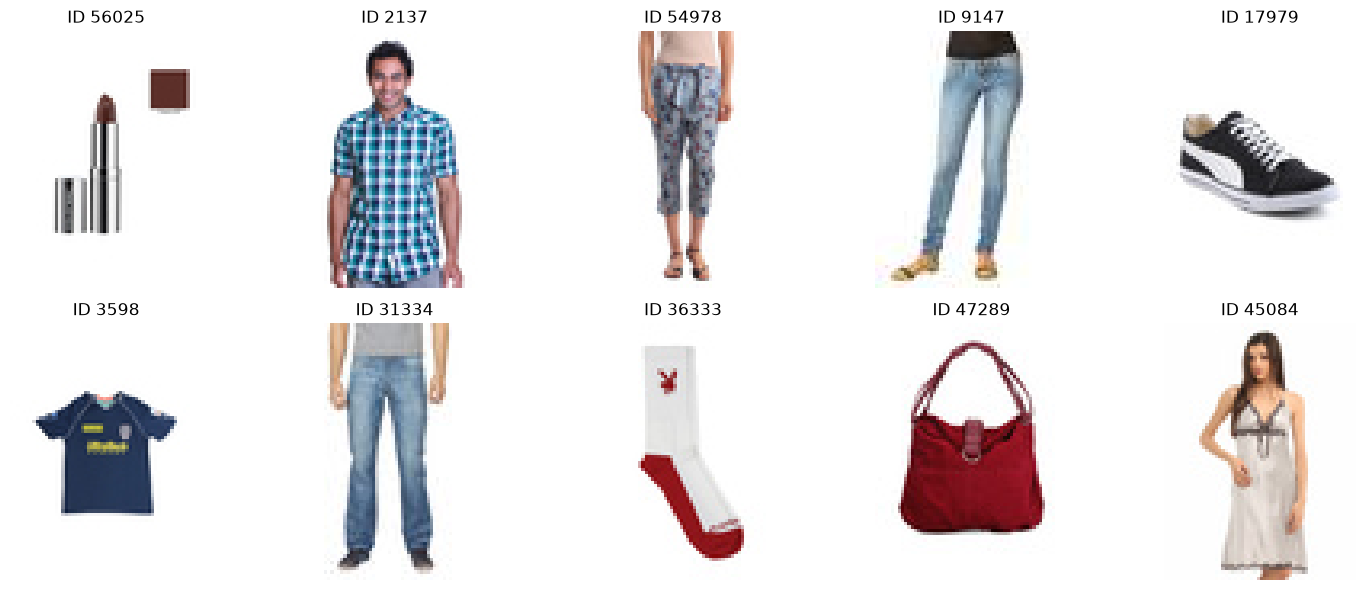

In [ ]:

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, (_, row) in zip(axes.ravel(), df.head(10).iterrows()):
    img = Image.open(row["image_path"]).convert("RGB")
    ax.imshow(img)
    ax.set_title(f"ID {row['id']}")
    ax.axis("off")
plt.tight_layout()
plt.show()


In [ ]:
from pathlib import Path

files = list(
    Path.home().glob(
        ".cache/huggingface/modules/transformers_modules/"
        "microsoft/Florence_hyphen_2_hyphen_large/*/modeling_florence2.py"
    )
)

for file in files:
    lines = file.read_text().splitlines()

    for i, line in enumerate(lines):
        if "class Florence2ForConditionalGeneration" in line:
            print(f"\nFile: {file}")
            print("\n".join(
                f"{j + 1}: {lines[j]}"
                for j in range(i, min(i + 18, len(lines)))
            ))
            break


File: /root/.cache/huggingface/modules/transformers_modules/microsoft/Florence_hyphen_2_hyphen_large/21a599d414c4d928c9032694c424fb94458e3594/modeling_florence2.py
2531: class Florence2ForConditionalGeneration(Florence2PreTrainedModel):
2532:     _tied_weights_keys = ["language_model.encoder.embed_tokens.weight", "language_model.decoder.embed_tokens.weight", "language_model.lm_head.weight"]
2533: 
2534:     def __init__(self, config: Florence2Config):
2535:         super().__init__(config)
2536:         assert config.vision_config.model_type == 'davit', 'only DaViT is supported for now'
2537:         self.vision_tower = DaViT.from_config(config=config.vision_config)
2538:         # remove unused layers 
2539:         del self.vision_tower.head
2540:         del self.vision_tower.norms
2541: 
2542:         self.vocab_size = config.vocab_size
2543:         self._attn_implementation = config._attn_implementation
2544:         self._build_image_projection_layers(config)
2545: 
2546:      

***7. Load Pre-trained AI Models***


In [ ]:

from transformers import AutoProcessor, AutoModelForCausalLM

FLORENCE_ID = "microsoft/Florence-2-large-ft"

print("Loading Florence-2...")
florence_processor = AutoProcessor.from_pretrained(
    FLORENCE_ID,
    trust_remote_code=True
)

florence = AutoModelForCausalLM.from_pretrained(
    FLORENCE_ID,
    trust_remote_code=True,
    torch_dtype=torch.float16 if DEVICE == "cuda" else torch.float32
)

florence = florence.to(DEVICE)

florence.eval()
print("Florence-2 loaded.")


Loading Florence-2...


generation_config.json:   0%|          | 0.00/51.0 [00:00<?, ?B/s]

Florence-2 loaded.


In [ ]:
print("Model class:", type(florence).__name__)

print("\nInput embedding module:")
print(type(florence.get_input_embeddings()).__name__)

print("\nLanguage model head module:")
print(type(florence.language_model.lm_head).__name__)

print("\nOutput embedding getter:")
print(florence.get_output_embeddings())

Model class: Florence2ForConditionalGeneration

Input embedding module:
Embedding

Language model head module:
Linear

Output embedding getter:
None


In [ ]:
test_img = Image.open(df.iloc[0]["image_path"]).convert("RGB")
caption = florence_caption(test_img)

print("Generated caption:", caption)
print("Caption is non-empty:", bool(caption.strip()))

Generated caption: A lipstick is shown on a white background. The lipstick is brown and has a silver cap. There is a brown square next to the lipstick.
Caption is non-empty: True


In [ ]:
print("Encoder embeddings:", florence.language_model.model.encoder.embed_tokens.weight.shape)
print("Decoder embeddings:", florence.language_model.model.decoder.embed_tokens.weight.shape)
print("Language model head:", florence.language_model.lm_head.weight.shape)

print("Encoder weights finite:",
      torch.isfinite(florence.language_model.model.encoder.embed_tokens.weight).all().item())
print("Decoder weights finite:",
      torch.isfinite(florence.language_model.model.decoder.embed_tokens.weight).all().item())
print("LM head weights finite:",
      torch.isfinite(florence.language_model.lm_head.weight).all().item())

Encoder embeddings: torch.Size([51289, 1024])
Decoder embeddings: torch.Size([51289, 1024])
Language model head: torch.Size([51289, 1024])
Encoder weights finite: True
Decoder weights finite: True
LM head weights finite: True



***8. Generate Image Captions Using Florence-2***

In [ ]:

def florence_caption(image):
    task = "<MORE_DETAILED_CAPTION>"
    image = image.resize((768, 768), Image.Resampling.BICUBIC)
    inputs = florence_processor(
        text=task,
        images=image,
        return_tensors="pt"
    )

    # Move tensors to the model's first device.
    inputs = {
        k: (v.to(florence.device) if hasattr(v, "to") else v)
        for k, v in inputs.items()
    }

    if "pixel_values" in inputs:
        inputs["pixel_values"] = inputs["pixel_values"].to(
            dtype=next(florence.parameters()).dtype
        )
    else:
        inputs = {k: (v.to(DEVICE) if hasattr(v, "to") else v)
                  for k, v in inputs.items()}

    with torch.no_grad():
        generated_ids = florence.generate(
        input_ids=inputs["input_ids"],
        pixel_values=inputs["pixel_values"],
        max_new_tokens=80,
        num_beams=3,
        do_sample=False,
        use_cache=False
      )


    generated = florence_processor.batch_decode(
        generated_ids,
        skip_special_tokens=False
    )[0]

    try:
        parsed = florence_processor.post_process_generation(
            generated,
            task=task,
            image_size=image.size
        )
        if isinstance(parsed, dict) and isinstance(parsed.get(task), str):
            return parsed[task].strip()
    except Exception:
        pass

    return re.sub(r"<[^>]+>", "", generated).strip()

test_img = Image.open(df.iloc[0]["image_path"]).convert("RGB")
print(florence_caption(test_img))


A lipstick is shown on a white background. The lipstick is brown and has a silver cap. There is a brown square next to the lipstick.


In [ ]:
test_img = Image.open(df.iloc[0]["image_path"]).convert("RGB")

caption = florence_caption(test_img)

print("Product:", df.iloc[0]["productDisplayName"])
print("Caption:", caption)

Product: Colorbar Soft Touch Drama Lipstick 027
Caption: A lipstick is shown on a white background. The lipstick is brown and has a silver cap. There is a brown square next to the lipstick.


***9. Extract Visual and Text Model Components (ViT and BERT)***


In [ ]:

from transformers import (
    ViTImageProcessor, ViTModel,
    AutoTokenizer, AutoModel
)

VIT_ID = "google/vit-base-patch16-224-in21k"
BERT_ID = "bert-base-uncased"

vit_processor = ViTImageProcessor.from_pretrained(VIT_ID)
vit = ViTModel.from_pretrained(VIT_ID).to(DEVICE).eval()

tokenizer = AutoTokenizer.from_pretrained(BERT_ID)
bert = AutoModel.from_pretrained(BERT_ID).to(DEVICE).eval()

print("ViT and BERT loaded.")


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

ViT and BERT loaded.



***10. Extract Visual Features Using Vision Transformer (ViT)***


In [ ]:

@torch.no_grad()
def vit_embedding(image):
    x = vit_processor(images=image, return_tensors="pt")
    x = {k: v.to(DEVICE) for k, v in x.items()}
    out = vit(**x)
    emb = out.last_hidden_state[:, 0, :]
    emb = torch.nn.functional.normalize(emb, p=2, dim=1)
    return emb[0].cpu().numpy().astype("float32")


In [ ]:
test_img = Image.open(df.iloc[0]["image_path"]).convert("RGB")

visual_vector = vit_embedding(test_img)

print("Embedding shape:", visual_vector.shape)
print("Data type:", visual_vector.dtype)
print("All values finite:", np.isfinite(visual_vector).all())
print("Embedding norm:", np.linalg.norm(visual_vector))

Embedding shape: (768,)
Data type: float32
All values finite: True
Embedding norm: 1.0



***11. Generate Text Embeddings Using BERT***


In [ ]:

@torch.no_grad()
def bert_embedding(text):
    enc = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=128
    )
    enc = {k: v.to(DEVICE) for k, v in enc.items()}
    out = bert(**enc)

    emb = out.last_hidden_state[:, 0, :]
    emb = torch.nn.functional.normalize(emb, p=2, dim=1)
    return emb[0].cpu().numpy().astype("float32")


In [ ]:
text_vector = bert_embedding(
    "A brown lipstick with a silver cap."
)

print("Embedding shape:", text_vector.shape)
print("Data type:", text_vector.dtype)
print("All values finite:", np.isfinite(text_vector).all())
print("Embedding norm:", np.linalg.norm(text_vector))

Embedding shape: (768,)
Data type: float32
All values finite: True
Embedding norm: 0.99999994


***12. Prepare Product Metadata for Embedding***


In [ ]:

METADATA_COLUMNS = [
    "gender",
    "masterCategory",
    "subCategory",
    "articleType",
    "baseColour",
    "season",
    "usage"
]

def metadata_text(row):
    parts = []
    for col in METADATA_COLUMNS:
        value = str(row.get(col, "")).strip()
        if value and value.lower() != "nan":
            parts.append(f"{col.replace('_', ' ')} {value}")
    return ", ".join(parts)

print(metadata_text(df.iloc[0]))


gender Women, masterCategory Personal Care, subCategory Lips, articleType Lipstick, baseColour Brown, season Spring, usage Casual



***13. Build Baseline and Proposed Fusion Representations***


In [ ]:

def normalize(v):
    v = np.asarray(v, dtype="float32")
    n = np.linalg.norm(v)
    return v / n if n > 0 else v

def baseline_fusion(visual, text):
    return normalize(np.concatenate([visual, text]))

def proposed_fusion(visual, text, metadata):
    return normalize(np.concatenate([visual, text, metadata]))


In [ ]:
baseline_vector = baseline_fusion(
    visual_vector,
    text_vector
)

metadata_vector = bert_embedding(metadata_text(df.iloc[0]))

proposed_vector = proposed_fusion(
    visual_vector,
    text_vector,
    metadata_vector
)

print("Baseline shape:", baseline_vector.shape)
print("Baseline norm:", np.linalg.norm(baseline_vector))
print("Proposed shape:", proposed_vector.shape)
print("Proposed norm:", np.linalg.norm(proposed_vector))

Baseline shape: (1536,)
Baseline norm: 1.0
Proposed shape: (2304,)
Proposed norm: 1.0



***14. Build the Multimodal Product Index***


In [ ]:

records = []

for _, row in tqdm(df.iterrows(), total=len(df), desc="Building multimodal index"):
    try:
        image = Image.open(row["image_path"]).convert("RGB")

        caption = florence_caption(image)
        visual = vit_embedding(image)
        text = bert_embedding(caption)

        meta_text = metadata_text(row)
        meta_emb = bert_embedding(meta_text)

        records.append({
            "id": int(row["id"]),
            "image_path": row["image_path"],
            "productDisplayName": str(row.get("productDisplayName", "")),
            "masterCategory": str(row.get("masterCategory", "")),
            "subCategory": str(row.get("subCategory", "")),
            "articleType": str(row.get("articleType", "")),
            "baseColour": str(row.get("baseColour", "")),
            "usage": str(row.get("usage", "")),
            "caption": caption,
            "metadata_text": meta_text,
            "visual": visual,
            "text": text,
            "metadata": meta_emb,
            "baseline": baseline_fusion(visual, text),
            "proposed": proposed_fusion(visual, text, meta_emb)
        })

    except Exception as e:
        print("Skipped", row["id"], ":", e)

print("Indexed:", len(records))

with open(INDEX / "records.pkl", "wb") as f:
    pickle.dump(records, f)

print("Saved index.")


Building multimodal index:   0%|          | 0/100 [00:00<?, ?it/s]

Indexed: 100
Saved index.



***15. Demonstrate Fashion Recommendations for an Unseen Query***

In [ ]:

# Load the full dataset for selecting an unseen query product.
# Keep df and the existing 100-product index unchanged.

df_all = pd.read_csv(CSV_PATH, on_bad_lines="skip")
df_all["image_path"] = df_all["id"].astype(str).apply(
    lambda x: str(IMAGE_SOURCE / f"{x}.jpg")
)
df_all = df_all[
    df_all["image_path"].apply(lambda p: Path(p).exists())
].dropna(subset=["productDisplayName"]).reset_index(drop=True)

indexed_ids = {int(record["id"]) for record in records}
df_all["id"] = pd.to_numeric(df_all["id"], errors="coerce")

remaining_products = df_all[
    df_all["id"].notna()
    & ~df_all["id"].astype(int).isin(indexed_ids)
]

if remaining_products.empty:
    raise ValueError("No unseen query products found in the full dataset.")

query_row = remaining_products.iloc[0]
QUERY_PATH = query_row["image_path"]

query_image = Image.open(QUERY_PATH).convert("RGB")
query_caption = florence_caption(query_image)
query_visual = vit_embedding(query_image)
query_text = bert_embedding(query_caption)

# Image-only query: metadata is approximated from its caption.
query_metadata_text = "product " + query_caption
query_metadata = bert_embedding(query_metadata_text)

q_baseline = baseline_fusion(query_visual, query_text)
q_proposed = proposed_fusion(
    query_visual, query_text, query_metadata
)

print("Query product:", query_row["productDisplayName"])
print("Query product ID:", int(query_row["id"]))
print("Query caption:", query_caption)
print("Query ID is in index:", int(query_row["id"]) in indexed_ids)
print("Unseen products available:", len(remaining_products))


Query product: Turtle Check Men Navy Blue Shirt
Query product ID: 15970
Query caption: A man is standing in front of a white background. He is wearing a black and white checkered shirt. He has dark hair and is wearing dark blue jeans. His arms are out to his sides and he has a slight smile on his face.
Query ID is in index: False
Unseen products available: 44312


***16. Retrieve Top-5 Recommendations Using Cosine Similarity***


In [ ]:

# Retrieve Top-K recommendations: baseline vs proposed

baseline_matrix = np.vstack([r["baseline"] for r in records])
proposed_matrix = np.vstack([r["proposed"] for r in records])

baseline_scores = baseline_matrix @ q_baseline
proposed_scores = proposed_matrix @ q_proposed

# Exclude the query product if it happens to be in the index.
indexed_record_ids = np.array([r["id"] for r in records])
baseline_scores[indexed_record_ids == int(query_row["id"])] = -np.inf
proposed_scores[indexed_record_ids == int(query_row["id"])] = -np.inf

baseline_order = np.argsort(-baseline_scores)[:TOP_K]
proposed_order = np.argsort(-proposed_scores)[:TOP_K]

def make_results(order, scores):
    return pd.DataFrame([
        {
            "rank": i + 1,
            "id": records[idx]["id"],
            "similarity": round(float(scores[idx]), 4),
            "category": records[idx]["subCategory"],
            "type": records[idx]["articleType"],
            "colour": records[idx]["baseColour"],
            "name": records[idx]["productDisplayName"]
        }
        for i, idx in enumerate(order)
    ])

baseline_results = make_results(baseline_order, baseline_scores)
proposed_results = make_results(proposed_order, proposed_scores)

print("QUERY PRODUCT:", query_row["productDisplayName"])
print("\nBASELINE — ViT + caption-BERT")
display(baseline_results)

print("\nPROPOSED — ViT + caption-BERT + metadata-BERT")
display(proposed_results)



QUERY PRODUCT: Turtle Check Men Navy Blue Shirt

BASELINE — ViT + caption-BERT


,rank,id,similarity,category,type,colour,name
0,1,18913,0.8963,Topwear,Shirts,Mustard,Levis Men Classics Gothic Mustard Shirt
1,2,2137,0.8447,Topwear,Shirts,Green,Basics Men White & Green Slim Fit Shirt
2,3,21023,0.8172,Topwear,Shirts,White,Black Coffee Men White Check Shirt
3,4,22356,0.8064,Topwear,Shirts,White,John Players Men Solid White Shirt
4,5,27558,0.8052,Topwear,Shirts,Lavender,Scullers Men Lavender Shirt



PROPOSED — ViT + caption-BERT + metadata-BERT


,rank,id,similarity,category,type,colour,name
0,1,18913,0.8105,Topwear,Shirts,Mustard,Levis Men Classics Gothic Mustard Shirt
1,2,2137,0.7752,Topwear,Shirts,Green,Basics Men White & Green Slim Fit Shirt
2,3,21023,0.7586,Topwear,Shirts,White,Black Coffee Men White Check Shirt
3,4,22356,0.7514,Topwear,Shirts,White,John Players Men Solid White Shirt
4,5,27558,0.7458,Topwear,Shirts,Lavender,Scullers Men Lavender Shirt


***17. Visualize the Recommended Products***


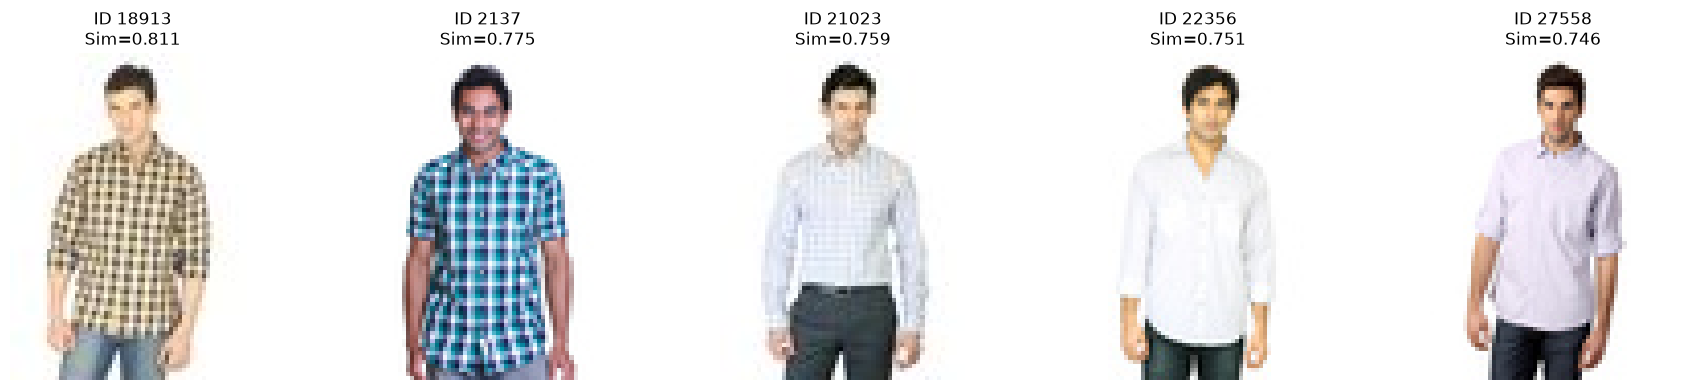

In [ ]:

fig, axes = plt.subplots(1, TOP_K, figsize=(18, 4))
for ax, idx in zip(axes, proposed_order):
    img = Image.open(records[idx]["image_path"]).convert("RGB")
    ax.imshow(img)
    ax.set_title(
        f"ID {records[idx]['id']}\n"
        f"Sim={proposed_scores[idx]:.3f}"
    )
    ax.axis("off")
plt.tight_layout()
plt.show()



***18. Evaluate Robustness Under Image Degradation***


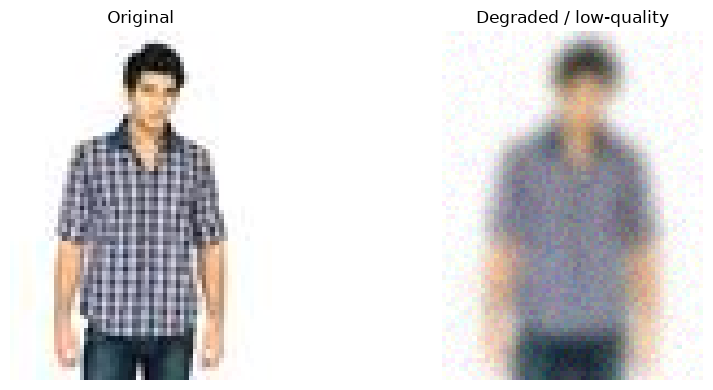

In [ ]:

def degrade_image(image, scale=0.35, blur_radius=2.0, noise_std=8):
    # Downscale then upscale to simulate low resolution.
    w, h = image.size
    small = image.resize((max(32, int(w*scale)), max(32, int(h*scale))))
    degraded = small.resize((w, h))

    # Blur.
    degraded = degraded.filter(ImageFilter.GaussianBlur(blur_radius))

    # Add mild Gaussian noise.
    arr = np.asarray(degraded).astype(np.float32)
    noise = np.random.normal(0, noise_std, arr.shape)
    arr = np.clip(arr + noise, 0, 255).astype(np.uint8)

    return Image.fromarray(arr)

degraded_query = degrade_image(query_image)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(query_image)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(degraded_query)
axes[1].set_title("Degraded / low-quality")
axes[1].axis("off")

plt.tight_layout()
plt.show()


***19. Compare Recommendations for Original and Degraded Images***


In [ ]:

# Compare original vs degraded query

# Create embeddings for the degraded query image.
degraded_caption = florence_caption(degraded_query)
degraded_visual = vit_embedding(degraded_query)
degraded_text = bert_embedding(degraded_caption)
degraded_metadata = bert_embedding("product " + degraded_caption)

degraded_baseline = baseline_fusion(
    degraded_visual, degraded_text
)
degraded_proposed = proposed_fusion(
    degraded_visual, degraded_text, degraded_metadata
)

# Calculate similarity scores.
db_scores = baseline_matrix @ degraded_baseline
dp_scores = proposed_matrix @ degraded_proposed

# Exclude the query product if it exists in the index.
indexed_record_ids = np.array([r["id"] for r in records])
db_scores[indexed_record_ids == int(query_row["id"])] = -np.inf
dp_scores[indexed_record_ids == int(query_row["id"])] = -np.inf

# Retrieve Top-K recommendations for the degraded image.
degraded_baseline_order = np.argsort(-db_scores)[:TOP_K]
degraded_proposed_order = np.argsort(-dp_scores)[:TOP_K]

# Compare original and degraded rankings.
def compare_rankings(original_order, degraded_order):
    original_ids = {records[i]["id"] for i in original_order}
    degraded_ids = {records[i]["id"] for i in degraded_order}
    overlap = len(original_ids & degraded_ids)
    return overlap, overlap / TOP_K

baseline_overlap, baseline_retention = compare_rankings(
    baseline_order, degraded_baseline_order
)
proposed_overlap, proposed_retention = compare_rankings(
    proposed_order, degraded_proposed_order
)

print("Original caption:")
print(query_caption)
print("\nDegraded caption:")
print(degraded_caption)

print("\nBASELINE")
print("Original best score:", round(float(baseline_scores.max()), 4))
print("Degraded best score:", round(float(db_scores.max()), 4))
print("Top-K products retained:", f"{baseline_overlap}/{TOP_K}")
print("Top-K retention rate:", f"{baseline_retention:.0%}")

print("\nPROPOSED")
print("Original best score:", round(float(proposed_scores.max()), 4))
print("Degraded best score:", round(float(dp_scores.max()), 4))
print("Top-K products retained:", f"{proposed_overlap}/{TOP_K}")
print("Top-K retention rate:", f"{proposed_retention:.0%}")

print("\nDegraded baseline recommendations:")
display(make_results(degraded_baseline_order, db_scores))

print("\nDegraded proposed recommendations:")
display(make_results(degraded_proposed_order, dp_scores))



Original caption:
A man is standing in front of a white background. He is wearing a black and white checkered shirt. He has dark hair and is wearing dark blue jeans. His arms are out to his sides and he has a slight smile on his face.

Degraded caption:
A blurry picture of a man. The man is not wearing a shirt. He has a hat on his head. He is wearing dark blue jeans.

BASELINE
Original best score: 0.8963
Degraded best score: 0.5552
Top-K products retained: 2/5
Top-K retention rate: 40%

PROPOSED
Original best score: 0.8105
Degraded best score: 0.5986
Top-K products retained: 2/5
Top-K retention rate: 40%

Degraded baseline recommendations:


,rank,id,similarity,category,type,colour,name
0,1,14949,0.5552,Topwear,Tshirts,Black,Status Quo Men Solid Black Tshirts
1,2,2338,0.5449,Topwear,Tshirts,White,Reebok Men Star White Polo T-shirt
2,3,21023,0.5429,Topwear,Shirts,White,Black Coffee Men White Check Shirt
3,4,27558,0.5416,Topwear,Shirts,Lavender,Scullers Men Lavender Shirt
4,5,16916,0.5408,Topwear,Sweaters,White,Spykar Men Stripes White Sweaters



Degraded proposed recommendations:


,rank,id,similarity,category,type,colour,name
0,1,14949,0.5986,Topwear,Tshirts,Black,Status Quo Men Solid Black Tshirts
1,2,2338,0.5937,Topwear,Tshirts,White,Reebok Men Star White Polo T-shirt
2,3,21023,0.5932,Topwear,Shirts,White,Black Coffee Men White Check Shirt
3,4,16916,0.5901,Topwear,Sweaters,White,Spykar Men Stripes White Sweaters
4,5,27558,0.5888,Topwear,Shirts,Lavender,Scullers Men Lavender Shirt


***20. Summarize the Experimental Configuration***


In [ ]:

# Compare the baseline and proposed system configurations.

experiment_summary = pd.DataFrame({
    "System": [
        "Paper-style baseline",
        "Proposed metadata-aware system"
    ],
    "Visual encoder": [
        "ViT",
        "ViT"
    ],
    "Caption generator": [
        "Florence-2",
        "Florence-2"
    ],
    "Text representation": [
        "BERT caption embedding",
        "BERT caption embedding"
    ],
    "Additional information": [
        "None",
        "BERT metadata embedding"
    ],
    "Fusion": [
        "Visual + caption",
        "Visual + caption + metadata"
    ],
    "Similarity metric": [
        "Cosine similarity",
        "Cosine similarity"
    ]
})

display(experiment_summary)



,System,Visual encoder,Caption generator,Text representation,Additional information,Fusion,Similarity metric
0,Paper-style baseline,ViT,Florence-2,BERT caption embedding,None,Visual + caption,Cosine similarity
1,Proposed metadata-aware system,ViT,Florence-2,BERT caption embedding,BERT metadata embedding,Visual + caption + metadata,Cosine similarity


***21. Multi-Query Evaluation and Robustness Analysis***

In [ ]:
# MULTI-QUERY EVALUATION
# Step 1: Inspect the existing index

print("Number of indexed records:", len(records))
print("Dataset rows available:", len(df))

if len(records) > 0:
    print("\nFirst record keys:")
    print(records[0].keys())

print("\nRequired variables available:")
print("Baseline fusion function:", "fuse_baseline" in globals())
print("Proposed fusion function:", "fuse_proposed" in globals())
print("ViT embedding function:", "vit_embedding" in globals())
print("BERT embedding function:", "bert_embedding" in globals())
print("Caption function:", "florence_caption" in globals())

Number of indexed records: 100
Dataset rows available: 100

First record keys:
dict_keys(['id', 'image_path', 'productDisplayName', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'usage', 'caption', 'metadata_text', 'visual', 'text', 'metadata', 'baseline', 'proposed'])

Required variables available:
Baseline fusion function: False
Proposed fusion function: False
ViT embedding function: True
BERT embedding function: True
Caption function: True


In [ ]:
# Step 2: Select multiple held-out query products

indexed_ids = {str(record["id"]) for record in records}

# Reload the full dataset table if df currently contains only the 100 sampled products.
# This uses the existing dataset files; it does not download the dataset again.
full_df = pd.read_csv(CSV_PATH, on_bad_lines="skip")
full_df["image_path"] = full_df["id"].astype(str).apply(
    lambda x: str(IMAGE_SOURCE / f"{x}.jpg")
)
full_df = full_df[
    full_df["image_path"].apply(lambda p: Path(p).exists())
].dropna(subset=["productDisplayName"]).copy()

# Exclude products already used in the index.
full_df["id_str"] = full_df["id"].astype(str)
heldout_df = full_df[~full_df["id_str"].isin(indexed_ids)].copy()

# Select 10 reproducible held-out queries.
query_df = heldout_df.sample(
    n=min(10, len(heldout_df)),
    random_state=123
).reset_index(drop=True)

print("Indexed products excluded:", len(indexed_ids))
print("Available held-out products:", len(heldout_df))
print("Selected query products:", len(query_df))

display(
    query_df[["id", "productDisplayName", "masterCategory", "articleType"]]
)

Indexed products excluded: 100
Available held-out products: 44312
Selected query products: 10


,id,productDisplayName,masterCategory,articleType
0,46877,Lino Perros Men Pack of 2 Socks,Accessories,Socks
1,56665,United Colors of Benetton Men Brown Shoes,Footwear,Casual Shoes
2,13345,Gini and Jony Kids Girls Solid White Capris,Apparel,Capris
3,46744,Nike Women Black Capris,Apparel,Capris
4,34248,Proline Men Grey T-shirt with Printed Detail,Apparel,Tshirts
5,17648,Converse Unisex Black Flip Flops,Footwear,Flip Flops
6,5701,Skechers Men's Flaunted Black Shoe,Footwear,Casual Shoes
7,5691,Skechers Men's Regions Off White Shoe,Footwear,Casual Shoes
8,48493,French Connection Women Black Skirt,Apparel,Skirts
9,42006,Baggit Women Beige Goofy Jhuti Wallet,Accessories,Wallets


In [ ]:
# Step 3: Inspect existing retrieval-related functions

import inspect

for name in [
    "vit_embedding",
    "bert_embedding",
    "florence_caption",
]:
    func = globals().get(name)
    print(f"\n--- {name} ---")
    if callable(func):
        print(inspect.signature(func))
    else:
        print("Not found")

print("\n--- Existing retrieval-related variables ---")
for name in [
    "query_baseline",
    "query_proposed",
    "baseline_query",
    "proposed_query",
    "cosine_similarity",
]:
    print(f"{name}: {name in globals()}")


--- vit_embedding ---
(image)

--- bert_embedding ---
(text)

--- florence_caption ---
(image)

--- Existing retrieval-related variables ---
query_baseline: False
query_proposed: False
baseline_query: False
proposed_query: False
cosine_similarity: True


In [ ]:
# Step 4: Test one held-out query

query_row = query_df.iloc[0]
query_image = Image.open(query_row["image_path"]).convert("RGB")

print("Query product:", query_row["productDisplayName"])
print("Query ID:", query_row["id"])

# Generate visual and caption embeddings
query_caption = florence_caption(query_image)
query_visual = vit_embedding(query_image)
query_text = bert_embedding(query_caption)

# Approximate metadata from the generated caption,
# consistent with the current image-query setup.
query_metadata_text = "product " + query_caption
query_metadata = bert_embedding(query_metadata_text)

print("\nCaption:", query_caption)
print("Visual embedding shape:", np.asarray(query_visual).shape)
print("Text embedding shape:", np.asarray(query_text).shape)
print("Metadata embedding shape:", np.asarray(query_metadata).shape)

# Compare against the stored index
baseline_scores = cosine_similarity(
    np.asarray(query_visual).reshape(1, -1)
    if False else np.asarray(query_visual).reshape(1, -1),
    np.stack([r["visual"] for r in records])
)

print("\nVisual-only test completed.")
print("Similarity scores shape:", baseline_scores.shape)

Query product: Lino Perros Men Pack of 2 Socks
Query ID: 46877

Caption: A pair of socks is shown. One sock is black and the other sock is tan. There are small dots on the tan sock.
Visual embedding shape: (768,)
Text embedding shape: (768,)
Metadata embedding shape: (768,)

Visual-only test completed.
Similarity scores shape: (1, 100)


In [ ]:
# Step 5: Verify stored index vector dimensions

print("Baseline vector shape:", np.asarray(records[0]["baseline"]).shape)
print("Proposed vector shape:", np.asarray(records[0]["proposed"]).shape)

print(
    "All baseline vectors have the same shape:",
    all(
        np.asarray(r["baseline"]).shape
        == np.asarray(records[0]["baseline"]).shape
        for r in records
    )
)

print(
    "All proposed vectors have the same shape:",
    all(
        np.asarray(r["proposed"]).shape
        == np.asarray(records[0]["proposed"]).shape
        for r in records
    )
)

Baseline vector shape: (1536,)
Proposed vector shape: (2304,)
All baseline vectors have the same shape: True
All proposed vectors have the same shape: True


In [ ]:
# Step 6: Inspect how the indexed vectors were constructed

r = records[0]

print("Product:", r["productDisplayName"])
print("Visual shape:", np.asarray(r["visual"]).shape)
print("Caption-text shape:", np.asarray(r["text"]).shape)
print("Metadata shape:", np.asarray(r["metadata"]).shape)
print("Baseline shape:", np.asarray(r["baseline"]).shape)
print("Proposed shape:", np.asarray(r["proposed"]).shape)

# Check whether fused vectors match normalized concatenation
def normalize_vector(v):
    v = np.asarray(v, dtype=np.float32).reshape(-1)
    norm = np.linalg.norm(v)
    return v / norm if norm > 0 else v

expected_baseline = normalize_vector(
    np.concatenate([r["visual"], r["text"]])
)
expected_proposed = normalize_vector(
    np.concatenate([r["visual"], r["text"], r["metadata"]])
)

print(
    "\nBaseline matches expected fusion:",
    np.allclose(expected_baseline, r["baseline"], atol=1e-5)
)
print(
    "Proposed matches expected fusion:",
    np.allclose(expected_proposed, r["proposed"], atol=1e-5)
)

Product: Colorbar Soft Touch Drama Lipstick 027
Visual shape: (768,)
Caption-text shape: (768,)
Metadata shape: (768,)
Baseline shape: (1536,)
Proposed shape: (2304,)

Baseline matches expected fusion: True
Proposed matches expected fusion: True


In [ ]:
# Step 7: Multi-query retrieval evaluation

from tqdm.auto import tqdm

def normalize_for_eval(vector):
    vector = np.asarray(vector, dtype=np.float32).reshape(-1)
    norm = np.linalg.norm(vector)
    return vector / norm if norm > 0 else vector

# Prepare the stored index vectors
baseline_index = np.stack([
    normalize_for_eval(r["baseline"]) for r in records
])
proposed_index = np.stack([
    normalize_for_eval(r["proposed"]) for r in records
])

results = []
top5_details = []

for _, query_row in tqdm(
    query_df.iterrows(),
    total=len(query_df),
    desc="Evaluating held-out queries"
):
    image = Image.open(query_row["image_path"]).convert("RGB")

    # Generate query representations
    caption = florence_caption(image)
    visual = normalize_for_eval(vit_embedding(image))
    text = normalize_for_eval(bert_embedding(caption))

    # Consistent with the current project:
    # metadata for an image-only query is approximated from its caption.
    metadata = normalize_for_eval(
        bert_embedding("product " + caption)
    )

    # Apply the same fusion convention used by the stored index
    baseline_query_vector = normalize_for_eval(
        np.concatenate([visual, text])
    )
    proposed_query_vector = normalize_for_eval(
        np.concatenate([visual, text, metadata])
    )

    # Retrieve the top 5 products from each system
    baseline_scores = cosine_similarity(
        baseline_query_vector.reshape(1, -1),
        baseline_index
    )[0]

    proposed_scores = cosine_similarity(
        proposed_query_vector.reshape(1, -1),
        proposed_index
    )[0]

    baseline_top5 = np.argsort(baseline_scores)[::-1][:5]
    proposed_top5 = np.argsort(proposed_scores)[::-1][:5]

    baseline_ids = [str(records[i]["id"]) for i in baseline_top5]
    proposed_ids = [str(records[i]["id"]) for i in proposed_top5]

    overlap = len(set(baseline_ids) & set(proposed_ids))

    results.append({
        "Query ID": query_row["id"],
        "Query product": query_row["productDisplayName"],
        "Baseline top-1": records[baseline_top5[0]]["productDisplayName"],
        "Baseline top-1 similarity": float(baseline_scores[baseline_top5[0]]),
        "Proposed top-1": records[proposed_top5[0]]["productDisplayName"],
        "Proposed top-1 similarity": float(proposed_scores[proposed_top5[0]]),
        "Top-5 overlap": overlap
    })

    for rank, idx in enumerate(baseline_top5, start=1):
        top5_details.append({
            "Query ID": query_row["id"],
            "System": "Baseline",
            "Rank": rank,
            "Recommended ID": records[idx]["id"],
            "Recommended product": records[idx]["productDisplayName"],
            "Cosine similarity": float(baseline_scores[idx])
        })

    for rank, idx in enumerate(proposed_top5, start=1):
        top5_details.append({
            "Query ID": query_row["id"],
            "System": "Proposed",
            "Rank": rank,
            "Recommended ID": records[idx]["id"],
            "Recommended product": records[idx]["productDisplayName"],
            "Cosine similarity": float(proposed_scores[idx])
        })

multi_query_results = pd.DataFrame(results)
multi_query_top5 = pd.DataFrame(top5_details)

print("\nMULTI-QUERY SUMMARY")
display(multi_query_results.round(4))

print("\nTOP-5 RECOMMENDATIONS FOR EACH QUERY")
display(multi_query_top5.round(4))

print("\nAGGREGATE DIAGNOSTIC METRICS")
print("Queries evaluated:", len(multi_query_results))
print(
    "Mean baseline top-1 similarity:",
    round(multi_query_results["Baseline top-1 similarity"].mean(), 4)
)
print(
    "Mean proposed top-1 similarity:",
    round(multi_query_results["Proposed top-1 similarity"].mean(), 4)
)
print(
    "Mean Top-5 overlap between systems:",
    round(multi_query_results["Top-5 overlap"].mean(), 2),
    "products out of 5"
)

Evaluating held-out queries:   0%|          | 0/10 [00:00<?, ?it/s]


MULTI-QUERY SUMMARY


,Query ID,Query product,Baseline top-1,Baseline top-1 similarity,Proposed top-1,Proposed top-1 similarity,Top-5 overlap
0,46877,Lino Perros Men Pack of 2 Socks,Playboy Men White & Red Socks,0.7709,Playboy Men White & Red Socks,0.7601,4
1,56665,United Colors of Benetton Men Brown Shoes,Fortune Men Brown Formal Shoes,0.8609,Fortune Men Brown Formal Shoes,0.8339,5
2,13345,Gini and Jony Kids Girls Solid White Capris,French Connection Men Blue Jeans,0.6841,French Connection Men Blue Jeans,0.7015,5
3,46744,Nike Women Black Capris,Puma Women Capri Sweat Grey Capris,0.7517,Puma Women Capri Sweat Grey Capris,0.7084,5
4,34248,Proline Men Grey T-shirt with Printed Detail,Reebok Men Star White Polo T-shirt,0.8296,Reebok Men Star White Polo T-shirt,0.7636,5
5,17648,Converse Unisex Black Flip Flops,Lotto Women's Wave Chic Black Purple Flip Flop,0.9076,Lotto Women's Wave Chic Black Purple Flip Flop,0.8236,5
6,5701,Skechers Men's Flaunted Black Shoe,Skechers Men's Traffics Brown Shoe,0.7683,Skechers Men's Traffics Brown Shoe,0.7651,5
7,5691,Skechers Men's Regions Off White Shoe,Skechers Men's Traffics Brown Shoe,0.8683,Skechers Men's Traffics Brown Shoe,0.8234,5
8,48493,French Connection Women Black Skirt,AND Women Red Dress,0.7846,AND Women Red Dress,0.7478,5
9,42006,Baggit Women Beige Goofy Jhuti Wallet,Ant Kids Girl's Green Kidswear,0.5932,Ant Kids Girl's Green Kidswear,0.6323,5



TOP-5 RECOMMENDATIONS FOR EACH QUERY


,Query ID,System,Rank,Recommended ID,Recommended product,Cosine similarity
0,46877,Baseline,1,36333,Playboy Men White & Red Socks,0.7709
1,46877,Baseline,2,9361,Puma Unisex FTPA Black Socks,0.7545
2,46877,Baseline,3,7824,Puma Women Cabana Racer II Purple Shoe,0.5750
3,46877,Baseline,4,38533,Puma Men White Future Cat Shoes,0.5632
4,46877,Baseline,5,6734,Puma Women Faas 300 Pink White Blue Shoe,0.5614
...,...,...,...,...,...,...
95,42006,Proposed,1,5575,Ant Kids Girl's Green Kidswear,0.6323
96,42006,Proposed,2,25055,Lino Perros Men Formal Brown Accessory Gift Set,0.6243
97,42006,Proposed,3,38691,Spice Art Women Pleated Purple Handbag,0.6236
98,42006,Proposed,4,47289,Baggit Women Red Bag,0.6014



AGGREGATE DIAGNOSTIC METRICS
Queries evaluated: 10
Mean baseline top-1 similarity: 0.7819
Mean proposed top-1 similarity: 0.756
Mean Top-5 overlap between systems: 4.9 products out of 5


In [ ]:
# Step 8: Save multi-query evaluation results

from pathlib import Path

RESULTS_DIR = WORK / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

summary_path = RESULTS_DIR / "multi_query_summary.csv"
top5_path = RESULTS_DIR / "multi_query_top5.csv"

multi_query_results.to_csv(summary_path, index=False)
multi_query_top5.to_csv(top5_path, index=False)

print("Saved summary:", summary_path)
print("Saved Top-5 details:", top5_path)
print("Summary rows:", len(multi_query_results))
print("Top-5 detail rows:", len(multi_query_top5))

Saved summary: /content/bilens_project/results/multi_query_summary.csv
Saved Top-5 details: /content/bilens_project/results/multi_query_top5.csv
Summary rows: 10
Top-5 detail rows: 100


In [ ]:
# Step 9: Check the existing image-degradation function

import inspect

for name in ["degrade_image", "create_degraded_image"]:
    func = globals().get(name)
    print(f"\n{name} exists:", callable(func))
    if callable(func):
        print("Function signature:", inspect.signature(func))


degrade_image exists: True
Function signature: (image, scale=0.35, blur_radius=2.0, noise_std=8)

create_degraded_image exists: False


In [ ]:
# Step 10: Multi-query robustness evaluation

robustness_results = []

# Reuse the index vectors prepared in Step 7.
for _, query_row in tqdm(
    query_df.iterrows(),
    total=len(query_df),
    desc="Testing robustness"
):
    original_image = Image.open(query_row["image_path"]).convert("RGB")
    degraded_image = degrade_image(original_image)

    # Generate captions and embeddings for both versions.
    original_caption = florence_caption(original_image)
    degraded_caption = florence_caption(degraded_image)

    original_visual = normalize_for_eval(vit_embedding(original_image))
    degraded_visual = normalize_for_eval(vit_embedding(degraded_image))

    original_text = normalize_for_eval(bert_embedding(original_caption))
    degraded_text = normalize_for_eval(bert_embedding(degraded_caption))

    # Query metadata is approximated from each generated caption.
    original_metadata = normalize_for_eval(
        bert_embedding("product " + original_caption)
    )
    degraded_metadata = normalize_for_eval(
        bert_embedding("product " + degraded_caption)
    )

    # Construct fused query vectors consistently with the index.
    original_baseline = normalize_for_eval(
        np.concatenate([original_visual, original_text])
    )
    degraded_baseline = normalize_for_eval(
        np.concatenate([degraded_visual, degraded_text])
    )

    original_proposed = normalize_for_eval(
        np.concatenate([original_visual, original_text, original_metadata])
    )
    degraded_proposed = normalize_for_eval(
        np.concatenate([degraded_visual, degraded_text, degraded_metadata])
    )

    # Retrieve Top-5 for original and degraded queries.
    orig_b_scores = cosine_similarity(
        original_baseline.reshape(1, -1), baseline_index
    )[0]
    deg_b_scores = cosine_similarity(
        degraded_baseline.reshape(1, -1), baseline_index
    )[0]

    orig_p_scores = cosine_similarity(
        original_proposed.reshape(1, -1), proposed_index
    )[0]
    deg_p_scores = cosine_similarity(
        degraded_proposed.reshape(1, -1), proposed_index
    )[0]

    orig_b_top5 = np.argsort(orig_b_scores)[::-1][:5]
    deg_b_top5 = np.argsort(deg_b_scores)[::-1][:5]
    orig_p_top5 = np.argsort(orig_p_scores)[::-1][:5]
    deg_p_top5 = np.argsort(deg_p_scores)[::-1][:5]

    baseline_retained = len(set(orig_b_top5) & set(deg_b_top5))
    proposed_retained = len(set(orig_p_top5) & set(deg_p_top5))

    robustness_results.append({
        "Query ID": query_row["id"],
        "Query product": query_row["productDisplayName"],
        "Baseline retained": baseline_retained,
        "Baseline retention (%)": baseline_retained / 5 * 100,
        "Proposed retained": proposed_retained,
        "Proposed retention (%)": proposed_retained / 5 * 100,
        "Baseline original top score": float(orig_b_scores[orig_b_top5[0]]),
        "Baseline degraded top score": float(deg_b_scores[deg_b_top5[0]]),
        "Proposed original top score": float(orig_p_scores[orig_p_top5[0]]),
        "Proposed degraded top score": float(deg_p_scores[deg_p_top5[0]]),
        "Original caption": original_caption,
        "Degraded caption": degraded_caption,
    })

robustness_df = pd.DataFrame(robustness_results)

print("\nMULTI-QUERY ROBUSTNESS RESULTS")
display(robustness_df.round(3))

print("\nAVERAGE TOP-5 RETENTION")
print(
    "Baseline:",
    round(robustness_df["Baseline retention (%)"].mean(), 2),
    "%"
)
print(
    "Proposed:",
    round(robustness_df["Proposed retention (%)"].mean(), 2),
    "%"
)

Testing robustness:   0%|          | 0/10 [00:00<?, ?it/s]


MULTI-QUERY ROBUSTNESS RESULTS


,Query ID,Query product,Baseline retained,Baseline retention (%),Proposed retained,Proposed retention (%),Baseline original top score,Baseline degraded top score,Proposed original top score,Proposed degraded top score,Original caption,Degraded caption
0,46877,Lino Perros Men Pack of 2 Socks,2,40.0,3,60.0,0.771,0.565,0.760,0.614,A pair of socks is shown. One sock is black an...,A shadow of a hand is on a white surface. The ...
1,56665,United Colors of Benetton Men Brown Shoes,1,20.0,2,40.0,0.861,0.529,0.834,0.583,A brown loafer is shown on a white background....,There is a shadow on the white paper. The shad...
2,13345,Gini and Jony Kids Girls Solid White Capris,0,0.0,0,0.0,0.684,0.482,0.701,0.526,A picture of a pair of white pants. The pants ...,The image is very blurry. There are small dots...
3,46744,Nike Women Black Capris,0,0.0,0,0.0,0.752,0.505,0.708,0.584,The image is of a pair of pants. The pants are...,The image is blurry. It is a black silhouette ...
4,34248,Proline Men Grey T-shirt with Printed Detail,2,40.0,1,20.0,0.830,0.542,0.764,0.586,A man is standing in front of a white backgrou...,A man is standing alone. He has short brown ha...
5,17648,Converse Unisex Black Flip Flops,2,40.0,2,40.0,0.908,0.525,0.824,0.578,A picture of a black flip flop. The image is v...,There is a shadow on the white surface. The su...
6,5701,Skechers Men's Flaunted Black Shoe,1,20.0,0,0.0,0.768,0.479,0.765,0.525,A black shoe is shown on a white background. T...,There is a shadow on the white surface. The sh...
7,5691,Skechers Men's Regions Off White Shoe,1,20.0,1,20.0,0.868,0.505,0.823,0.567,A white shoe has black stripes on the side of ...,There is a shadow. The shadow looks like a sho...
8,48493,French Connection Women Black Skirt,2,40.0,2,40.0,0.785,0.569,0.748,0.607,A woman is wearing a purple shirt and a black ...,A blurry image of a foot. The foot appears to ...
9,42006,Baggit Women Beige Goofy Jhuti Wallet,1,20.0,1,20.0,0.593,0.483,0.632,0.551,This is a rectangular object that looks like a...,The image is blurry. The background is white. ...



AVERAGE TOP-5 RETENTION
Baseline: 24.0 %
Proposed: 24.0 %


In [ ]:
# Step 11: Save multi-query robustness results

robustness_path = RESULTS_DIR / "multi_query_robustness.csv"

robustness_df.to_csv(robustness_path, index=False)

print("Saved robustness results:", robustness_path)
print("Queries evaluated:", len(robustness_df))
print(
    "Baseline mean retention:",
    round(robustness_df["Baseline retention (%)"].mean(), 2),
    "%"
)
print(
    "Proposed mean retention:",
    round(robustness_df["Proposed retention (%)"].mean(), 2),
    "%"
)

Saved robustness results: /content/bilens_project/results/multi_query_robustness.csv
Queries evaluated: 10
Baseline mean retention: 24.0 %
Proposed mean retention: 24.0 %
